In [23]:
RUN_ID = "20261030T220121_51392060"

CV_IDS = []  # Empty = all evaluated CVs

### 1. Load evaluation results

In [24]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src" / "cv_extraction").is_dir()
        and (path / "evaluation").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Could not locate the project root.")

RESULTS_DIR = ROOT / "evaluation" / "results"
RUN_DIR = RESULTS_DIR / RUN_ID

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

available_ids = sorted(
    path.name
    for path in RESULTS_DIR.iterdir()
    if path.is_dir() and (path / "summary.json").exists()
)

print("Available evaluation IDs:")
print("\n".join(available_ids))

if not RUN_DIR.is_dir():
    raise FileNotFoundError(f"Evaluation not found: {RUN_ID}")

config = read_json(RUN_DIR / "config.json")
summary = read_json(RUN_DIR / "summary.json")

reports = [
    read_json(path)
    for path in sorted((RUN_DIR / "documents").glob("*/repeat_*.json"))
]

if CV_IDS:
    reports = [
        report for report in reports
        if report["document_id"] in CV_IDS
    ]

if not reports:
    raise ValueError("No document reports match the selection.")

evaluated = [
    report for report in reports
    if report["status"] == "evaluated"
]

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
})

print(f"\nRun: {RUN_ID}")
print(f"Selected attempts: {len(reports)}")
print(f"Evaluated attempts: {len(evaluated)}")
print(f"Source: {config.get('source_path')}")
print(f"Evaluator version: {config.get('evaluator_version')}")


print("Automatic scores exclude free-text content and provenance.")

Available evaluation IDs:
20261029T101434_7476b507
20261029T215235_8e602a1a
20261030T220121_51392060

Run: 20261030T220121_51392060
Selected attempts: 1
Evaluated attempts: 1
Source: results\20261030T220121_51392060
Evaluator version: 1.2
Automatic scores exclude free-text content and provenance.


### 2. Coverage and review status
Check this before interpreting accuracy. Failed or missing extractions do not contribute to the factual scores.

,cv_id,repetition,status,matching_review,content_review
0,CV002,1,evaluated,True,pending


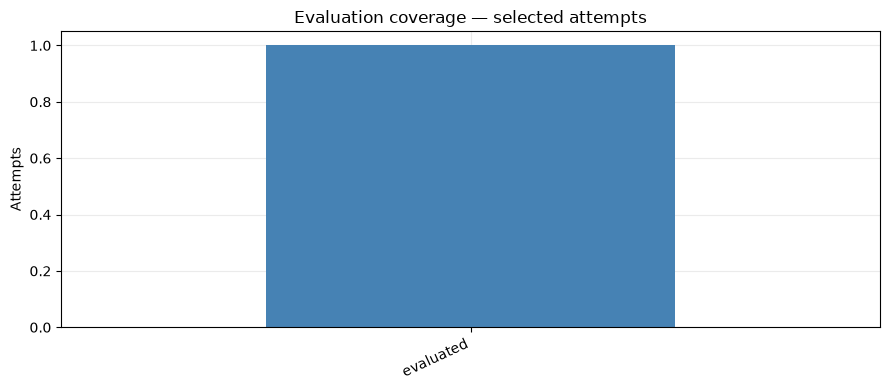

In [25]:
coverage = pd.DataFrame([
    {
        "cv_id": report["document_id"],
        "repetition": report["repetition"],
        "status": report["status"],
        "matching_review": report.get("matching_review_required", False),
        "content_review": report.get("content_review", {}).get(
            "status", "not_available"
        ),
    }
    for report in reports
])

display(coverage)

coverage["status"].value_counts().plot.bar(
    color="steelblue", figsize=(9, 4)
)
plt.title("Evaluation coverage — selected attempts")
plt.ylabel("Attempts")
plt.xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 3. Prepare accuracy tables
Counts are pooled across the selected CVs and repetitions. This also makes the remaining cells respect CV_IDS.

In [26]:
COUNT_COLUMNS = ["correct", "missing", "incorrect", "unexpected"]

def calculate_metrics(counts):
    values = {
        name: int(counts.get(name, 0))
        for name in COUNT_COLUMNS
    }

    correct = values["correct"]
    expected = correct + values["missing"] + values["incorrect"]
    predicted = correct + values["unexpected"] + values["incorrect"]

    return {
        **values,
        "expected_facts": expected,
        "predicted_facts": predicted,
        "precision": correct / predicted if predicted else np.nan,
        "recall": correct / expected if expected else np.nan,
        "f1": (
            2 * correct / (expected + predicted)
            if expected + predicted else np.nan
        ),
    }

category_rows = []
document_rows = []

for report in evaluated:
    document_rows.append({
        "cv_id": report["document_id"],
        "repetition": report["repetition"],
        **report["overall"],
    })

    for category, scores in report["categories"].items():
        category_rows.append({
            "cv_id": report["document_id"],
            "repetition": report["repetition"],
            "category": category,
            **scores,
        })

documents = pd.DataFrame(document_rows)
category_attempts = pd.DataFrame(category_rows)

if not evaluated:
    raise ValueError(
        "No scored attempts. Check coverage, reference availability and validation errors."
    )

category_counts = (
    category_attempts.groupby("category")[COUNT_COLUMNS].sum()
)

categories = pd.DataFrame({
    name: calculate_metrics(row)
    for name, row in category_counts.iterrows()
}).T

overall = calculate_metrics(
    documents[COUNT_COLUMNS].sum()
)

display(
    pd.DataFrame([overall], index=["Selected attempts"])
    .style.format(
        {name: "{:.1%}" for name in ["precision", "recall", "f1"]},
        na_rep="N/A",
    )
)

display(
    categories.style.format(
        {name: "{:.1%}" for name in ["precision", "recall", "f1"]},
        na_rep="N/A",
    )
)

,correct,missing,incorrect,unexpected,expected_facts,predicted_facts,precision,recall,f1
Selected attempts,49,5,3,16,57,68,72.1%,86.0%,78.4%


,correct,missing,incorrect,unexpected,expected_facts,predicted_facts,precision,recall,f1
certifications,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,N/A,N/A,N/A
education,14.000000,0.000000,1.000000,1.000000,15.000000,16.000000,87.5%,93.3%,90.3%
languages,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,N/A,N/A,N/A
personal_information,7.000000,1.000000,0.000000,2.000000,8.000000,9.000000,77.8%,87.5%,82.4%
projects,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,N/A,N/A,N/A
skills,10.000000,0.000000,1.000000,3.000000,11.000000,14.000000,71.4%,90.9%,80.0%
training,0.000000,0.000000,0.000000,4.000000,0.000000,4.000000,0.0%,N/A,0.0%
work_experience,18.000000,4.000000,1.000000,6.000000,23.000000,25.000000,72.0%,78.3%,75.0%


### 4. Precision, recall and F1 by category
Categories with no expected or predicted facts are omitted rather than displayed as 0%.

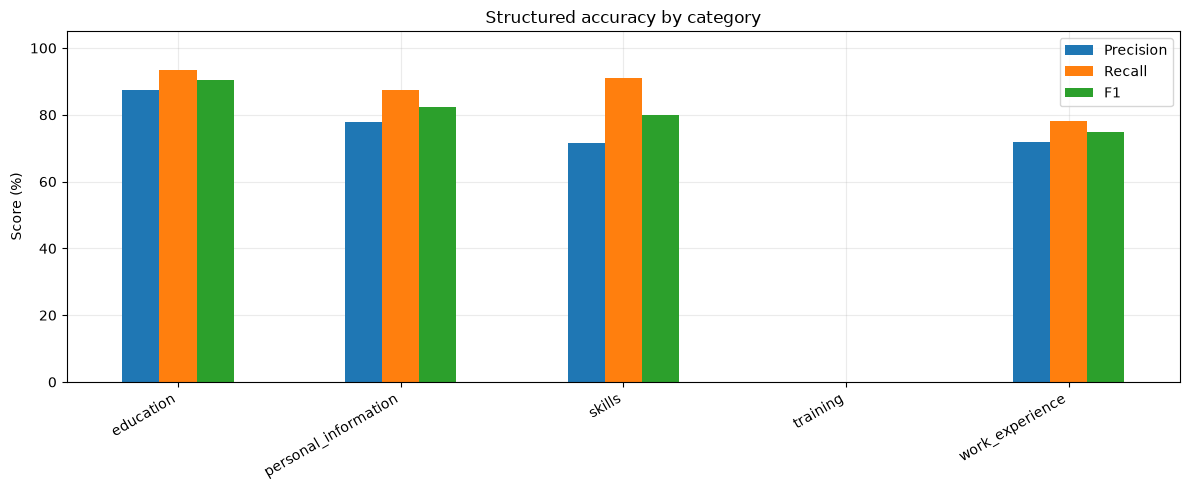

In [27]:
scored_categories = categories[
    (categories["expected_facts"] + categories["predicted_facts"]) > 0
]

ax = (
    scored_categories[["precision", "recall", "f1"]] * 100
).plot.bar()

ax.set_title("Structured accuracy by category")
ax.set_ylabel("Score (%)")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.legend(["Precision", "Recall", "F1"])

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 5. What kind of errors occur in each category?
Absolute counts reveal whether a category is mainly losing information or adding incorrect information.

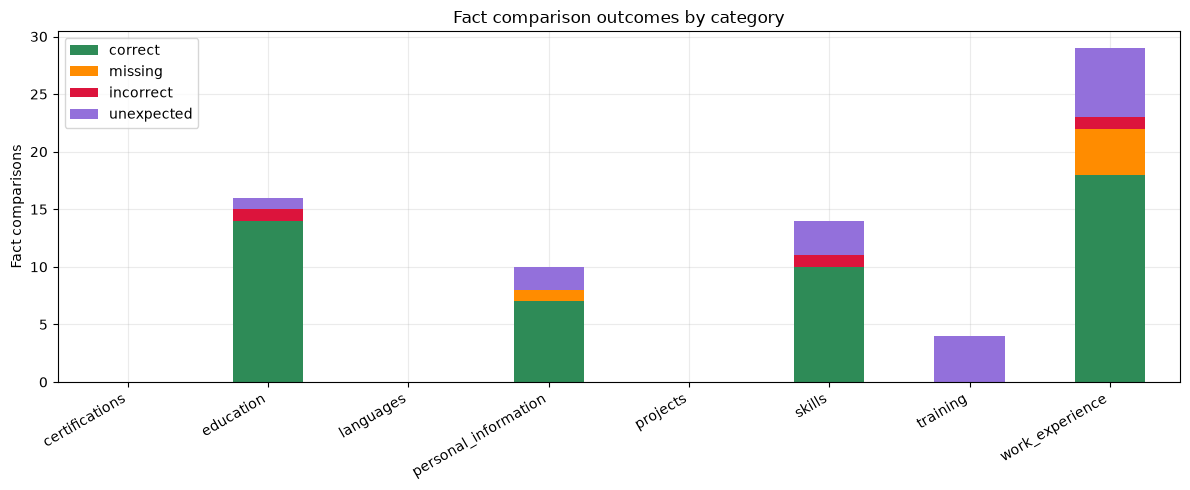

In [28]:
categories[COUNT_COLUMNS].plot.bar(
    stacked=True,
    color=["seagreen", "darkorange", "crimson", "mediumpurple"],
)

plt.title("Fact comparison outcomes by category")
plt.ylabel("Fact comparisons")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 6. Accuracy per CV
Repetitions are pooled within each CV.

,correct,missing,incorrect,unexpected,expected_facts,predicted_facts,precision,recall,f1
CV002,49.000000,5.000000,3.000000,16.000000,57.000000,68.000000,72.1%,86.0%,78.4%


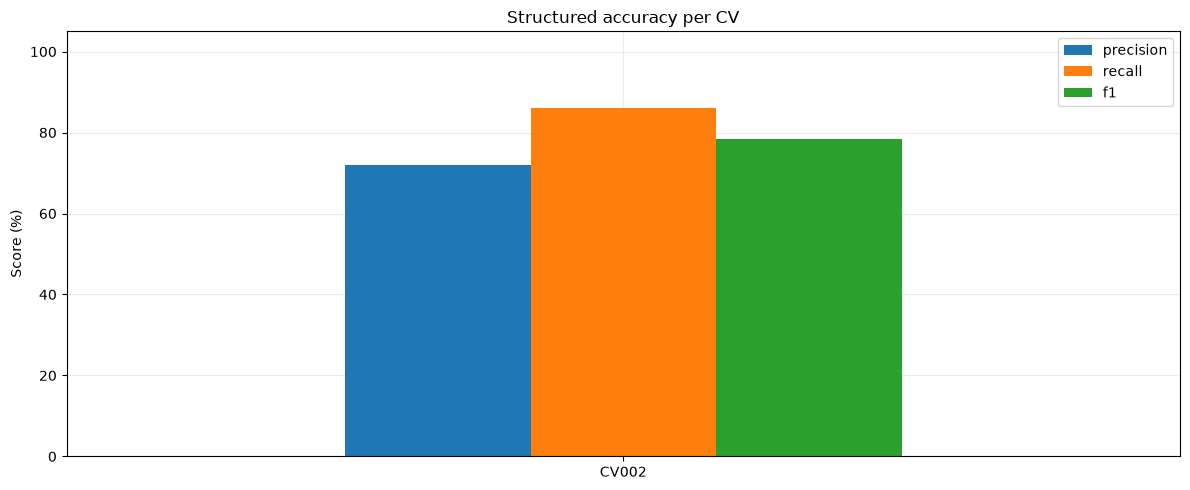

In [29]:
document_counts = documents.groupby("cv_id")[COUNT_COLUMNS].sum()

per_cv = pd.DataFrame({
    cv_id: calculate_metrics(row)
    for cv_id, row in document_counts.iterrows()
}).T

display(
    per_cv.style.format(
        {name: "{:.1%}" for name in ["precision", "recall", "f1"]},
        na_rep="N/A",
    )
)

(per_cv[["precision", "recall", "f1"]] * 100).plot.bar()

plt.title("Structured accuracy per CV")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7. Category F1 heatmap per CV
This makes it easy to spot cases such as one CV doing well on employment but poorly on skills.

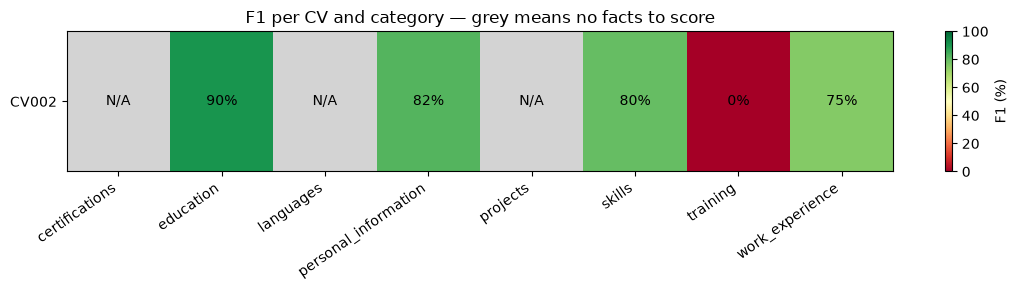

In [30]:
heatmap_rows = []

for (cv_id, category), group in category_attempts.groupby(
    ["cv_id", "category"]
):
    scores = calculate_metrics(group[COUNT_COLUMNS].sum())
    heatmap_rows.append({
        "cv_id": cv_id,
        "category": category,
        "f1": scores["f1"],
    })

heatmap = pd.DataFrame(heatmap_rows).pivot(
    index="cv_id", columns="category", values="f1"
)

values = heatmap.to_numpy(dtype=float) * 100
cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(
    figsize=(max(10, len(heatmap.columns) * 1.4),
             max(3, len(heatmap.index) * 0.8))
)

image = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=cmap,
    vmin=0,
    vmax=100,
    aspect="auto",
)

ax.set_xticks(
    range(len(heatmap.columns)),
    heatmap.columns,
    rotation=35,
    ha="right",
)
ax.set_yticks(range(len(heatmap.index)), heatmap.index)
ax.grid(False)

for row in range(values.shape[0]):
    for column in range(values.shape[1]):
        value = values[row, column]
        ax.text(
            column, row,
            "N/A" if np.isnan(value) else f"{value:.0f}%",
            ha="center", va="center",
        )

ax.set_title("F1 per CV and category — grey means no facts to score")
fig.colorbar(image, ax=ax, label="F1 (%)")
plt.tight_layout()
plt.show()

### 8. Inspect the actual differences
Change the filters to investigate a specific CV, category or error type.

In [31]:
FILTER_CV = None          # Example: "CV012"
FILTER_CATEGORY = None    # Example: "skills"
FILTER_RESULT = None      # "missing", "incorrect", or "unexpected"
MAX_ROWS = 60

difference_rows = []

for report in evaluated:
    for difference in report.get("differences", []):
        path = difference["path"]
        category = path.split(".", 1)[0].split("[", 1)[0]

        difference_rows.append({
            "cv_id": report["document_id"],
            "repetition": report["repetition"],
            "category": category,
            **difference,
        })

differences = pd.DataFrame(difference_rows, columns=[
    "cv_id", "repetition", "category", "path",
    "result", "expected", "actual",
])

filtered = differences.copy()

if FILTER_CV:
    filtered = filtered[filtered["cv_id"].eq(FILTER_CV)]

if FILTER_CATEGORY:
    filtered = filtered[filtered["category"].eq(FILTER_CATEGORY)]

if FILTER_RESULT:
    filtered = filtered[filtered["result"].eq(FILTER_RESULT)]

print(f"{len(filtered)} differences match the filters.")

with pd.option_context(
    "display.max_colwidth", 120,
    "display.max_rows", MAX_ROWS,
):
    display(filtered.head(MAX_ROWS))

24 differences match the filters.


,cv_id,repetition,category,path,result,expected,actual
0,CV002,1,personal_information,personal_information.phones[reference:0],missing,+49 176 *** *** **,NaN
1,CV002,1,personal_information,personal_information.phones[prediction:0],unexpected,NaN,+49 176 *******
2,CV002,1,personal_information,personal_information.weblinks[0->0].platform,unexpected,NaN,website
3,CV002,1,work_experience,work_experience[0->0].location,unexpected,NaN,"Bremen, Germany"
4,CV002,1,work_experience,work_experience[0->0].skills[reference:0],missing,Meteor,NaN
5,CV002,1,work_experience,work_experience[1->1].location,unexpected,NaN,"Bremen, Germany"
6,CV002,1,work_experience,work_experience[1->1].skills[reference:0],missing,IBM XPages,NaN
7,CV002,1,work_experience,work_experience[1->1].skills[reference:1],missing,Notes Domino,NaN
8,CV002,1,work_experience,work_experience[1->1].skills[reference:2],missing,We4IT Aveedo,NaN
9,CV002,1,work_experience,work_experience[2->2].location,unexpected,NaN,"Bremen, Germany"


### 9. Matching warnings and provenance

These are separate from the structured accuracy charts.

Record pairs requiring review:


,cv_id,repetition,path,reference_index,prediction_index,reason
0,CV002,1,work_experience,3,3,Ambiguous or non-exact identity alignment; rev...
1,CV002,1,education,0,0,Ambiguous or non-exact identity alignment; rev...
2,CV002,1,skills,6,2,Ambiguous or non-exact identity alignment; rev...



Provenance checks:


,cv_id,repetition,policy,correct,missing,incorrect,unexpected
0,CV002,1,empty,0,0,0,10


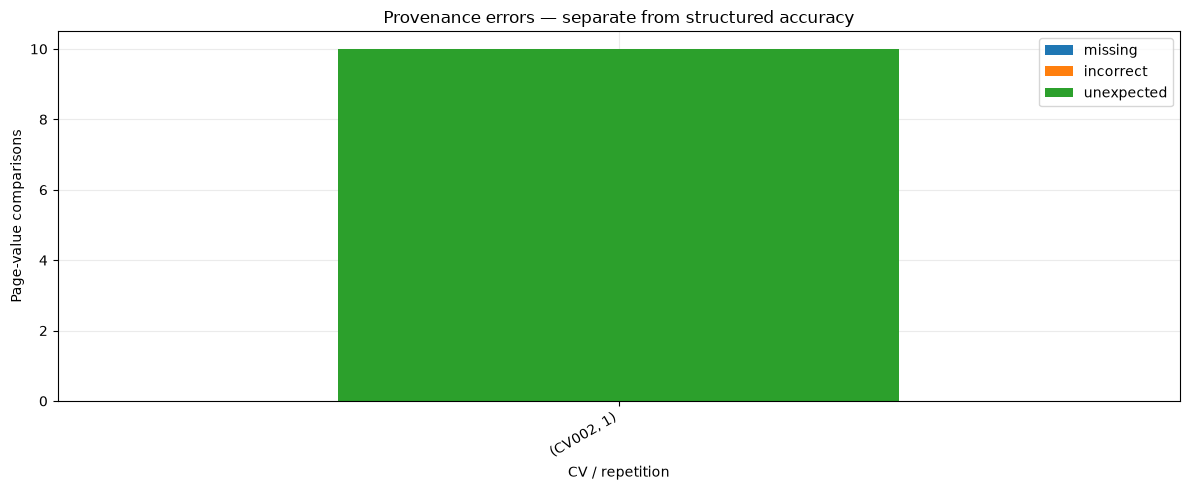

In [32]:
warning_rows = []
provenance_rows = []

for report in evaluated:
    for warning in report.get("matching_warnings", []):
        warning_rows.append({
            "cv_id": report["document_id"],
            "repetition": report["repetition"],
            **warning,
        })

    provenance = report.get("provenance", {})
    provenance_rows.append({
        "cv_id": report["document_id"],
        "repetition": report["repetition"],
        "policy": provenance.get("policy"),
        **{
            name: provenance.get(name, 0)
            for name in COUNT_COLUMNS
        },
    })

print("Record pairs requiring review:")
display(pd.DataFrame(warning_rows))

print("\nProvenance checks:")
provenance_table = pd.DataFrame(provenance_rows)
display(provenance_table)

if provenance_table[["missing", "incorrect", "unexpected"]].to_numpy().sum():
    provenance_table.set_index(
        ["cv_id", "repetition"]
    )[["missing", "incorrect", "unexpected"]].plot.bar(stacked=True)

    plt.title("Provenance errors — separate from structured accuracy")
    plt.ylabel("Page-value comparisons")
    plt.xlabel("CV / repetition")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### 10. Read-only manual content inspection
Select a CV and compare the descriptive content. This displays the saved checklist without changing it.

In [33]:
REVIEW_CV = "CV001"
REVIEW_REPETITION = 1

report = next(
    (
        item for item in evaluated
        if item["document_id"] == REVIEW_CV
        and item["repetition"] == REVIEW_REPETITION
    ),
    None,
)

if report is None:
    print("No evaluated report matches this selection.")
else:
    review = report.get("content_review", {})

    print("Review status:", review.get("status", "unknown"))
    display(pd.DataFrame(review.get("checklist", {})).T)

    for side in ["reference", "prediction"]:
        print(f"\n{'=' * 20} {side.upper()} {'=' * 20}")

        for item in review.get(side, []):
            print(f"\n{item['path']}")
            content = item["content"]

            if isinstance(content, str):
                print(content)
            else:
                print(json.dumps(content, ensure_ascii=False, indent=2))

No evaluated report matches this selection.
